# Ai2020 Enertech · 7월 BoL DFN 단계별 재현

**입력:** `260610 저율데이터 1.xlsx`, `260610 저율데이터 2.xlsx`,
`260902 Enertech셀 데이터 모음.xlsx`, `260703 BoL 데이터 6-5.xlsx`,
`260703 BoL 데이터 6-6.xlsx`, `260703 BoL 데이터 6-8.xlsx`.
Colab에서는 여섯 파일을 `/content`에 올리고 위에서부터 실행한다. 로컬에서는
`AI2020_DATA_DIR` 환경변수로 폴더를 지정할 수 있다. 원본은 읽기만 한다.

현대차 참고 노트북과 같이 **입력 검사 → 정적 파라미터/OCP → window → CC/CV DFN →
시간축 전압 RMSE → hysteresis 진단** 순서다. 셀 종류와 실험 형식이 달라
입력 파서와 Ai2020 파라미터만 바꿨다. 7월 세 실물 셀은 각각 완전한 기록 순서로
실행한다. 첫 기록 이전 이력은 알 수 없어 첫 휴지 종점전압을 공통 qOCV에 역산한
균일 초기 상태로 시작한다. CV 종료는 원본과 같은 C/10으로 둔다.


In [ ]:
import os, sys, subprocess, importlib.metadata as metadata
try:
    installed = metadata.version("pybamm")
except metadata.PackageNotFoundError:
    installed = None
if installed != "26.8.0.0":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "pybamm==26.8.0.0", "openpyxl", "scipy", "matplotlib"])
import numpy as np
import pandas as pd
import pybamm
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import cumulative_trapezoid
try:
    from IPython.display import display
except ImportError:
    display = print
print("PyBaMM", pybamm.__version__)


In [ ]:
DATA_DIR = Path(os.environ.get("AI2020_DATA_DIR", "/content" if Path("/content").exists() else "."))
OUTPUT_DIR = DATA_DIR / "ai2020_july_bol_results"
OUTPUT_DIR.mkdir(exist_ok=True)
NAMES = {
    "june1": "260610 저율데이터 1.xlsx", "june2": "260610 저율데이터 2.xlsx",
    "ocp": "260902 Enertech셀 데이터 모음.xlsx",
    "6-5": "260703 BoL 데이터 6-5.xlsx", "6-6": "260703 BoL 데이터 6-6.xlsx",
    "6-8": "260703 BoL 데이터 6-8.xlsx",
}
PATHS = {key: DATA_DIR / name for key, name in NAMES.items()}
missing = [path.name for path in PATHS.values() if not path.exists()]
if missing:
    try:
        from google.colab import files
    except ImportError:
        files = None
    if files is not None:
        print("다음 6개 입력 파일을 업로드하세요:", list(NAMES.values()))
        files.upload()
        missing = [path.name for path in PATHS.values() if not path.exists()]
if missing:
    raise FileNotFoundError(f"{DATA_DIR}에 필요한 파일이 없습니다: {missing}")
for key in ("june1", "june2", "6-5", "6-6", "6-8"):
    sheets = set(pd.ExcelFile(PATHS[key]).sheet_names)
    if "record" not in sheets or (key.startswith("6-") and "step" not in sheets):
        raise ValueError(f"{PATHS[key].name}: record/step 시트를 확인하세요. 보유 시트={sheets}")
legacy_sheets = set(pd.ExcelFile(PATHS["ocp"]).sheet_names)
if not {"CATHODE_GITT", "PARAMETER_PRIOR"}.issubset(legacy_sheets):
    raise ValueError("260902 파일에 CATHODE_GITT/PARAMETER_PRIOR 시트가 필요합니다")
print("입력 확인 완료:", *[p.name for p in PATHS.values()], sep="\n - ")


## 1. Geometry와 OCP 입력

Ai2020 원래 전극 두께(음극/분리막/양극 76.5/25/68 µm), 활물질 체적분율
(0.61/0.62), 공극률(0.33/0.50/0.32)은 유지한다. SEM 반경은
3.7542/4.2387 µm, 공통 overlap 면적은 `45.4 mm × 51.0 mm × 34면`으로
교체한다. OCP는 Ai2020 graphite와 기존 양극 7-7/7-8 GITT의 방향별
휴지전압 평균이다. 새 9월 양극 GITT는 역방향이 완결되지 않아 이 기준에 섞지 않는다.

**선정 근거:** 6월 C/50 두 셀의 완전 cycle 2–5 평균 qOCV에서, 끝점 오차
10 mV 이내와 양극 절대 stoichiometry anchor 조건을 만족한 후보 중
`Ai2020 graphite + 기존 양극 GITT`가 SoC 2–98% qOCV RMSE **6.24 mV**로
가장 낮았다. 기존 음극 + 기존 양극은 8.22 mV, 두 전극 모두 Ai2020은
16.35 mV였다. 새 양극 후보의 수치상 5.03 mV는 역방향 73.6% 완료와
절대 anchor 부족으로 선정 대상에서 제외했다. 이 비교는 저율 OCP 선택의
근거이며 고율 전압이나 음극 전위 정확성의 증명은 아니다.


In [ ]:
F = 96485.33212
AI_K = 1e-11 * F
Q_CELL_REFERENCE_AH = 2.3565276563125
WINDOW = {"x0": 0.003806223746311917, "x100": 0.9542212582298351,
          "y0": 0.9707457852378695, "y100": 0.4316424031304631}
AI_WINDOW = {"x0": 0.0065, "x100": 0.84, "y0": 0.9651, "y100": 0.435}
DSN_GITT = 4.170774145968247e-14
DSP_GITT = 6.888175323807748e-14
KP_EIS_MEAN = 5.696439229422568e-7  # P4 v1/v2 평균 Rct=19.454 ohm cm2
KN_JULY_FIT = 1.4502357402082455e-6  # July voltage fit; 독립 실측 물성 아님

def clean_curve(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    good = np.isfinite(x) & np.isfinite(y)
    x, y = x[good], y[good]
    order = np.argsort(x)
    x, y = x[order], y[order]
    unique, inverse = np.unique(x, return_inverse=True)
    if len(unique) == len(x):
        return x, y
    return unique, np.bincount(inverse, weights=y) / np.bincount(inverse)

def mean_overlap(curves, n=3000):
    lo = max(float(c[0].min()) for c in curves)
    hi = min(float(c[0].max()) for c in curves)
    if hi <= lo:
        raise ValueError("양극 GITT의 공통 stoichiometry 범위가 없습니다")
    grid = np.linspace(lo, hi, n)
    return grid, np.mean([np.interp(grid, *c) for c in curves], axis=0)

raw = pybamm.ParameterValues("Ai2020")
prior = pd.read_excel(PATHS["ocp"], sheet_name="PARAMETER_PRIOR", header=7)
disk_diameter = float(prior.loc[prior.parameter.eq("disk_diameter_m"), "value"].iloc[0])
disk_area = np.pi * (disk_diameter / 2)**2
qp_disk = (F * float(raw["Maximum concentration in positive electrode [mol.m-3]"])
           * float(raw["Positive electrode active material volume fraction"])
           * float(raw["Positive electrode thickness [m]"]) * disk_area / 3600)
gitt = pd.read_excel(PATHS["ocp"], sheet_name="CATHODE_GITT", header=8)
replicate_curves = {"lithiation": [], "delithiation": []}
for channel in ("7-7", "7-8"):
    for pulse, direction in (("discharge_pulse", "lithiation"),
                             ("charge_pulse", "delithiation")):
        part = gitt[(gitt.source_channel.eq(channel)) & gitt.pulse_direction.eq(pulse)]
        q = part.Qcum_Ah.to_numpy(float)
        v = part.Vrest_V.to_numpy(float)
        if not len(q):
            raise ValueError(f"양극 GITT {channel}/{pulse} 누락")
        y = (1 - float(np.max(q))/qp_disk) + q/qp_disk if direction == "lithiation" else 1 - q/qp_disk
        replicate_curves[direction].append(clean_curve(y, v))
yl, ul = mean_overlap(replicate_curves["lithiation"])
yd, ud = mean_overlap(replicate_curves["delithiation"])
y_min, y_max = max(yl.min(), yd.min()), min(yl.max(), yd.max())
y_grid = np.linspace(y_min, y_max, 3000)
u_lith = np.interp(y_grid, yl, ul)
u_delith = np.interp(y_grid, yd, ud)
u_positive = 0.5 * (u_lith + u_delith)

def interp_ocp(grid, values, name):
    def fn(sto):
        return pybamm.Interpolant(grid, values, [sto], name=name,
                                  interpolator="linear", extrapolate=True)
    return fn

UP_EQUILIBRIUM = interp_ocp(y_grid, u_positive, "Old cathode GITT equilibrium OCP")
UP_LITH = interp_ocp(y_grid, u_lith, "Old cathode GITT lithiation OCP")
UP_DELITH = interp_ocp(y_grid, u_delith, "Old cathode GITT delithiation OCP")
nominal_grid = np.linspace(.001, .999, 3001)
un_nominal = np.asarray([float(np.asarray(raw["Negative electrode OCP [V]"](
    pybamm.Scalar(float(sto))).evaluate()).reshape(-1)[0]) for sto in nominal_grid])
up_nominal = np.asarray([float(np.asarray(raw["Positive electrode OCP [V]"](
    pybamm.Scalar(float(sto))).evaluate()).reshape(-1)[0]) for sto in nominal_grid])

def qocv_curve(window, positive="nominal", soc=None):
    z = np.linspace(0, 1, 1001) if soc is None else np.asarray(soc)
    x = window["x0"] + z * (window["x100"] - window["x0"])
    y = window["y0"] - z * (window["y0"] - window["y100"])
    up = np.interp(y, y_grid, u_positive) if positive == "measured" else np.interp(y, nominal_grid, up_nominal)
    return np.asarray(up) - np.interp(x, nominal_grid, un_nominal)

print("공통 면적 [cm²] =", 45.4 * 51.0 * 34 / 100)
print("양극 GITT overlap y =", (round(y_min, 5), round(y_max, 5)))
plt.plot(y_grid, u_lith, label="lithiation")
plt.plot(y_grid, u_delith, label="delithiation")
plt.plot(y_grid, u_positive, label="equilibrium mean", lw=2)
plt.xlabel("Positive stoichiometry y"); plt.ylabel("OCP [V]"); plt.legend(); plt.grid(alpha=.2)
plt.show()


## 2. C/50 qOCV와 stoichiometry window

참고 노트북처럼 충·방전 각각의 완전 CC 용량으로 SoC를 정규화한 뒤 평균한다.
첫 방전은 부분 충전 직후이므로 제외한다. 선정된 window는 별도 최적화 없이
명시된 고정 입력으로 가져오며, 업로드된 C/50 파일로 qOCV 적합도를 다시 검증한다.
`c_s,max`는 `Q_n Δx = Q_p Δy = Q_cell`에 맞춘 **유효값**이다.


In [ ]:
def c50_target():
    soc = np.linspace(0, 1, 1001)
    charge_curves, discharge_curves, qchg, qdis = [], [], [], []
    for key in ("june1", "june2"):
        record = pd.read_excel(PATHS[key], sheet_name="record")
        blocks = record["Step Type"].astype(str).ne(record["Step Type"].astype(str).shift()).cumsum()
        found = {"CC Chg": [], "CC DChg": []}
        for _, part in record.groupby(blocks):
            kind = str(part["Step Type"].iloc[0])
            if kind not in found:
                continue
            q = pd.to_numeric(part["Capacity(Ah)"], errors="coerce").to_numpy(float)
            v = pd.to_numeric(part["Voltage(V)"], errors="coerce").to_numpy(float)
            i = float(pd.to_numeric(part["Current(A)"], errors="coerce").median())
            good = np.isfinite(q) & np.isfinite(v)
            q, v = q[good], v[good]
            if len(q) < 50 or max(q) < 2.2 or abs(i) > 0.06:
                continue
            qmax = float(max(q))
            z = q/qmax if kind == "CC Chg" else 1-q/qmax
            x, u = clean_curve(z, v)
            found[kind].append((qmax, np.interp(soc, x, u)))
        for capacity, values in found["CC Chg"]:
            qchg.append(capacity); charge_curves.append(values)
        for capacity, values in found["CC DChg"][1:]:
            qdis.append(capacity); discharge_curves.append(values)
    if (len(charge_curves), len(discharge_curves)) != (8, 8):
        raise ValueError(f"C/50 완전 branch 8+8개 예상, 실제 {len(charge_curves)}+{len(discharge_curves)}")
    charge = np.mean(charge_curves, axis=0)
    discharge = np.mean(discharge_curves, axis=0)
    return soc, 0.5*(charge+discharge), 0.5*(np.mean(qchg)+np.mean(qdis))

soc_grid, measured_qocv, qcell = c50_target()
predicted_qocv = qocv_curve(WINDOW, "measured", soc_grid)
mask = (soc_grid >= .02) & (soc_grid <= .98)
qocv_rmse = 1000*np.sqrt(np.mean((predicted_qocv[mask]-measured_qocv[mask])**2))
area = .0454 * .0510 * 34
qn = qcell/(WINDOW["x100"]-WINDOW["x0"])
qp = qcell/(WINDOW["y0"]-WINDOW["y100"])
csn = 3600*qn/(F*area*float(raw["Negative electrode thickness [m]"])
               *float(raw["Negative electrode active material volume fraction"]))
csp = 3600*qp/(F*area*float(raw["Positive electrode thickness [m]"])
               *float(raw["Positive electrode active material volume fraction"]))
print(f"Qcell={qcell:.9f} Ah, qOCV 2–98% RMSE={qocv_rmse:.3f} mV")
print(f"x0/x100={WINDOW['x0']:.6f}/{WINDOW['x100']:.6f}, y0/y100={WINDOW['y0']:.6f}/{WINDOW['y100']:.6f}")
print(f"Qn/Qp={qn:.6f}/{qp:.6f} Ah, effective csmax n/p={csn:.1f}/{csp:.1f} mol/m³")
if abs(qcell-Q_CELL_REFERENCE_AH) > 0.002 or abs(qocv_rmse-6.2426573) > 2.0:
    raise ValueError("C/50 qOCV/용량이 선정 기준과 다릅니다. 입력 파일·GITT 축을 확인하세요")
plt.plot(soc_grid, measured_qocv, label="June C/50 mean", color="black")
plt.plot(soc_grid, predicted_qocv, label="Ai2020 graphite + old cathode GITT")
plt.xlabel("Full-cell SoC"); plt.ylabel("qOCV [V]"); plt.legend(); plt.grid(alpha=.2); plt.show()


## 3. DFN 단계별 충방전 비교

`S0` Ai2020 원형에서 확인된 전해질 확산계수 단위 보정 `D_e×10⁻⁴`만 공통 적용;
`S1` SEM 반경·overlap; `S2` 양극 측정 OCP; `S3` 선택 window와 이에 맞춘
유효 `c_s,max`; 이후 D_s, EIS 평균 k_p, 7월 fitting k_n을 **하나씩/누적** 반영한다.
`k_n`은 EIS 확정 측정값이 아니므로 결과 이름에 `July fitted`라고 표시한다.
이 k_n은 다른 고정 D_s/k_p 조합에서 얻은 과거 fitting값을 **전이 적용**한
진단이고 S8 조합에 새로 fitting한 결과가 아니다. 전해질 Bruggeman과 t+는
모든 stage에서 고정한다.
초기 상태는 각 stage의 qOCV와 첫 휴지 종점전압으로 다시 정한다.


In [ ]:
def scaled(fn, factor):
    def wrapped(*args, **kwargs):
        return factor * fn(*args, **kwargs)
    return wrapped

SCENARIOS = [
    ("S0 Ai2020", False, False, False, False, False, False, False),
    ("S1 +Geometry", True, False, False, False, False, False, False),
    ("S2 +OCP", True, True, False, False, False, False, False),
    ("S3 +Window", True, True, True, False, False, False, False),
    ("S4 +Dsn", True, True, True, True, False, False, False),
    ("S5 +Dsp", True, True, True, False, True, False, False),
    ("S6 +Dsn+Dsp", True, True, True, True, True, False, False),
    ("S7 +kp only", True, True, True, False, False, True, False),
    ("S8 +Dsn+Dsp+kp", True, True, True, True, True, True, False),
    ("S9 +July fitted kn", True, True, True, True, True, True, True),
]
BRANCHES = {7:(.5,"Charge"),10:(.5,"Discharge"),12:(1.,"Charge"),
            15:(1.,"Discharge"),17:(2.,"Charge"),20:(2.,"Discharge")}

def values_for(geometry, ocp, window, dsn, dsp, kp, kn, hys=False):
    p = raw.copy()
    p.update({"Electrolyte diffusivity [m2.s-1]":
              scaled(raw["Electrolyte diffusivity [m2.s-1]"],1e-4)})
    if geometry:
        p.update({"Negative particle radius [m]":3.7542e-6,
                  "Positive particle radius [m]":4.2387e-6,
                  "Electrode height [m]":.0454,
                  "Electrode width [m]":.0510,
                  "Number of electrodes connected in parallel to make a cell":34})
    if ocp:
        p.update({"Positive electrode OCP [V]": UP_EQUILIBRIUM})
    if window:
        p.update({"Maximum concentration in negative electrode [mol.m-3]":csn,
                  "Maximum concentration in positive electrode [mol.m-3]":csp})
    if dsn:
        p.update({"Negative particle diffusivity [m2.s-1]":DSN_GITT})
    if dsp:
        p.update({"Positive particle diffusivity [m2.s-1]":DSP_GITT})
    if kp:
        p.update({"Positive electrode exchange-current density [A.m-2]":
                  scaled(raw["Positive electrode exchange-current density [A.m-2]"],KP_EIS_MEAN/AI_K)})
    if kn:
        p.update({"Negative electrode exchange-current density [A.m-2]":
                  scaled(raw["Negative electrode exchange-current density [A.m-2]"],KN_JULY_FIT/AI_K)})
    if hys:
        p.update({"Positive electrode lithiation OCP [V]":UP_LITH,
                  "Positive electrode delithiation OCP [V]":UP_DELITH,
                  "Positive particle lithiation hysteresis decay rate":lambda sto,temp:3.2+0*sto,
                  "Positive particle delithiation hysteresis decay rate":lambda sto,temp:3.2+0*sto,
                  "Initial hysteresis state in positive electrode":0.0})
    return p

def step_records(record, row):
    part = record[(record.Date>=row["Oneset Date"]) & (record.Date<=row["End Date"])
                  & (record["Step Type"].astype(str)==str(row["Step Type"]))]
    if part.empty:
        raise ValueError(f"Step {row['Step Number']} 기록 없음")
    return part

def command(row, record):
    kind = str(row["Step Type"])
    if kind=="Rest":
        duration=int(round((row["End Date"]-row["Oneset Date"]).total_seconds()))
        return f"Rest for {duration} seconds"
    if kind=="CV Chg":
        return "Hold at 4.2 V until C/10"
    current = float(np.nanmedian(np.abs(pd.to_numeric(step_records(record,row)["Current(A)"], errors="coerce"))))
    if kind=="CC Chg":
        return f"Charge at {current:.8f} A until 4.2 V"
    if kind=="CC DChg":
        return f"Discharge at {current:.8f} A until 3.0 V"
    raise ValueError(kind)

def load_july(key):
    step=pd.read_excel(PATHS[key],sheet_name="step")
    record=pd.read_excel(PATHS[key],sheet_name="record")
    for col in ("Oneset Date","End Date"):
        step[col]=pd.to_datetime(step[col])
    record["Date"]=pd.to_datetime(record["Date"])
    step=step[(step["Step Number"]>=1)&(step["Step Number"]<=20)].sort_values("Step Number")
    expected=["Rest","CC Chg","CV Chg","Rest","CC DChg","Rest",
              "CC Chg","CV Chg","Rest","CC DChg","Rest","CC Chg","CV Chg",
              "Rest","CC DChg","Rest","CC Chg","CV Chg","Rest","CC DChg"]
    if step["Step Type"].astype(str).tolist()!=expected:
        raise ValueError(f"{key}: 1–20단계 레시피가 예상과 다릅니다")
    return step,record

JULY={key:load_july(key) for key in ("6-5","6-6","6-8")}

def simulate_history(key, spec, hys=False):
    _, geometry, ocp, window, dsn, dsp, kp, kn = spec
    p=values_for(geometry,ocp,window,dsn,dsp,kp,kn,hys)
    endpoints=WINDOW if window else AI_WINDOW
    qv=qocv_curve(endpoints,"measured" if ocp else "nominal",soc_grid)
    step,record=JULY[key]
    rest_v=float(step.loc[step["Step Number"].eq(1),"End Voltage(V)"].iloc[0])
    order=np.argsort(qv,kind="stable")
    v_unique,index=np.unique(qv[order],return_index=True)
    z0=float(np.interp(rest_v,v_unique,soc_grid[order][index]))
    x0=endpoints["x0"]+z0*(endpoints["x100"]-endpoints["x0"])
    y0=endpoints["y0"]-z0*(endpoints["y0"]-endpoints["y100"])
    p.update({"Initial concentration in negative electrode [mol.m-3]":
              x0*float(p["Maximum concentration in negative electrode [mol.m-3]"]),
              "Initial concentration in positive electrode [mol.m-3]":
              y0*float(p["Maximum concentration in positive electrode [mol.m-3]"]),
              "Initial temperature [K]":298.15,"Ambient temperature [K]":298.15})
    dynamic=step[step["Step Number"]>=2]
    commands=[command(row,record) for _,row in dynamic.iterrows()]
    exp=pybamm.Experiment([tuple(commands)],period="10 seconds")
    options={"open-circuit potential":("single","one-state hysteresis" if hys else "single"),
             "thermal":"isothermal"}
    simulation=pybamm.Simulation(pybamm.lithium_ion.DFN(options),parameter_values=p,
                                 experiment=exp,
                                 var_pts={"x_n":15,"x_s":15,"x_p":15,"r_n":15,"r_p":15},
                                 solver=pybamm.IDAKLUSolver(rtol=1e-6,atol=1e-8))
    sol=simulation.solve()
    if len(sol.cycles[0].steps)!=len(commands):
        raise RuntimeError(f"{key}: 계산 단계 수가 원본과 다릅니다")
    by_num=dict(zip(dynamic["Step Number"].astype(int),sol.cycles[0].steps))
    return step,record,by_num,z0

def compare_branch(cell, scenario, number, step, record, by_num):
    rate,direction=BRANCHES[number]
    row=step.loc[step["Step Number"].eq(number)].iloc[0]
    measured=step_records(record,row)
    te=(measured.Date-measured.Date.iloc[0]).dt.total_seconds().to_numpy(float)/60
    ve=pd.to_numeric(measured["Voltage(V)"],errors="coerce").to_numpy(float)
    valid=np.isfinite(te)&np.isfinite(ve)
    te,ve=te[valid],ve[valid]
    solution=by_num[number]
    tm=np.asarray(solution["Time [s]"].entries,float)/60
    tm=tm-tm[0]
    vm=np.asarray(solution["Terminal voltage [V]"].entries,float)
    stop=min(te[-1],tm[-1])
    grid=np.linspace(0,stop,100)
    residual=1000*(np.interp(grid,tm,vm)-np.interp(grid,te,ve))
    metric={"scenario":scenario,"cell":cell,"rate_C":rate,"direction":direction,
            "RMSE_overlap_mV":float(np.sqrt(np.mean(residual**2))),
            "max_abs_mV":float(np.max(np.abs(residual))),
            "coverage_pct":100*stop/te[-1],"experiment_end_min":float(te[-1]),
            "model_end_min":float(tm[-1])}
    return metric,(te,ve,tm,vm)

print(f"7월 셀 {list(JULY)} 로드 완료. 시나리오 {len(SCENARIOS)}개 × 3셀 계산 준비")


In [6]:
# 전체 시나리오가 10개×3셀이라 수 분 이상 걸릴 수 있다. 실패는 숨기지 않고
# failure.csv에 기록하며, 필수 단계 S0–S3가 하나라도 실패하면 아래에서 중단한다.
metric_rows, curves, failures = [], {}, []
for spec in SCENARIOS:
    name=spec[0]
    for cell in JULY:
        print(f"실행: {name}, {cell}", flush=True)
        try:
            step,record,by_num,z0=simulate_history(cell,spec)
            for number in BRANCHES:
                metric,curve=compare_branch(cell,name,number,step,record,by_num)
                metric["initial_soc_from_first_rest_pct"]=100*z0
                metric_rows.append(metric)
                curves[(name,cell,number)]=curve
        except Exception as exc:
            failures.append({"scenario":name,"cell":cell,"error":repr(exc)})
            print("실패:",repr(exc))
metrics=pd.DataFrame(metric_rows)
failures_df=pd.DataFrame(failures,columns=["scenario","cell","error"])
metrics.to_csv(OUTPUT_DIR/"stage_metrics_by_cell.csv",index=False)
failures_df.to_csv(OUTPUT_DIR/"failures.csv",index=False)
if failures_df.scenario.isin([s[0] for s in SCENARIOS[:4]]).any():
    raise RuntimeError("기본/Geometry/OCP/window 단계 실패. failures.csv 확인")
summary=metrics.groupby(["scenario","rate_C","direction"],as_index=False).agg(
    n_cells=("cell","nunique"),mean_RMSE_mV=("RMSE_overlap_mV","mean"),
    worst_max_abs_mV=("max_abs_mV","max"),min_coverage_pct=("coverage_pct","min"))
summary.to_csv(OUTPUT_DIR/"stage_summary.csv",index=False)
display(summary.pivot(index="scenario",columns=["rate_C","direction"],values="mean_RMSE_mV")
          .reindex([s[0] for s in SCENARIOS]).round(2))
display(summary[["scenario","rate_C","direction","n_cells","min_coverage_pct"]])
print("결과 저장:",OUTPUT_DIR)


검증 실행: 7월 3셀 × 10시나리오, 실패 0건. 각 모델의 CC 겹침 구간 RMSE (mV).


rate_C                0.5              1.0              2.0          
direction          Charge Discharge Charge Discharge Charge Discharge
scenario                                                             
S0 Ai2020           89.52     72.81  92.31     71.56  93.09     49.80
S1 +Geometry        78.76     28.94  77.20     30.48  73.33     42.76
S2 +OCP             53.89     59.40  58.42     57.25  59.72     42.86
S3 +Window          46.51     42.90  54.83     49.33  59.41     47.78
S4 +Dsn             46.46     42.87  54.49     49.30  59.03     47.82
S5 +Dsp             49.48     47.89  58.44     57.88  61.41     44.60
S6 +Dsn+Dsp         49.45     48.07  58.18     58.22  61.05     44.76
S7 +kp only         40.27     38.06  52.65     46.05  62.81     56.45
S8 +Dsn+Dsp+kp      41.44     35.92  49.92     40.87  53.58     28.55
S9 +July fitted kn  47.31     45.30  56.61     53.26  59.63     36.97

실험 CC 시간의 최소 커버리지 (%).


rate_C                0.5              1.0              2.0          
direction          Charge Discharge Charge Discharge Charge Discharge
scenario                                                             
S0 Ai2020           100.0     100.0  100.0     100.0  100.0     100.0
S1 +Geometry        100.0     100.0  100.0     100.0   98.1      95.8
S2 +OCP             100.0     100.0   99.6     100.0   95.8      97.0
S3 +Window           97.4      99.1   95.4      98.6   90.1      94.1
S4 +Dsn              97.4      99.1   95.4      98.7   90.2      94.1
S5 +Dsp              99.8     100.0  100.0     100.0  100.0      99.8
S6 +Dsn+Dsp          99.8     100.0  100.0     100.0  100.0      99.8
S7 +kp only          96.4      98.8   93.4      98.2   85.9      93.5
S8 +Dsn+Dsp+kp       98.9      99.8   99.1     100.0   98.3      99.3
S9 +July fitted kn   99.9     100.0  100.0     100.0  100.0      99.9

In [7]:
# 모든 stage가 존재하는 동일 시간 창으로 다시 점수화해 파라미터 반영 효과를 비교한다.
# 조기 cutoff가 가장 빠른 stage에 맞춰 창이 짧아지므로 위의 coverage 표도 함께 본다.
common_rows=[]
for cell in JULY:
    for number,(rate,direction) in BRANCHES.items():
        available=[s[0] for s in SCENARIOS if (s[0],cell,number) in curves]
        if len(available)!=len(SCENARIOS):
            continue
        te,ve,_,_=curves[(available[0],cell,number)]
        stop=min([te[-1]]+[curves[(name,cell,number)][2][-1] for name in available])
        grid=np.linspace(0,stop,100)
        measured=np.interp(grid,te,ve)
        for name in available:
            _,_,tm,vm=curves[(name,cell,number)]
            residual=1000*(np.interp(grid,tm,vm)-measured)
            common_rows.append({"cell":cell,"rate_C":rate,"direction":direction,
                                "scenario":name,"common_RMSE_mV":float(np.sqrt(np.mean(residual**2))),
                                "common_coverage_pct":100*stop/te[-1]})
common=pd.DataFrame(common_rows)
common.to_csv(OUTPUT_DIR/"stage_common_window_by_cell.csv",index=False)
common_summary=common.groupby(["scenario","rate_C","direction"],as_index=False).agg(
    n_cells=("cell","nunique"),mean_common_RMSE_mV=("common_RMSE_mV","mean"),
    min_common_coverage_pct=("common_coverage_pct","min"))
common_summary.to_csv(OUTPUT_DIR/"stage_common_window_summary.csv",index=False)
display(common_summary.pivot(index="scenario",columns=["rate_C","direction"],
                             values="mean_common_RMSE_mV").reindex([s[0] for s in SCENARIOS]).round(2))
print("공통창 최소 커버리지(조건별):")
display(common_summary.groupby(["rate_C","direction"])["min_common_coverage_pct"].first().round(2))


전 시나리오 동일 시간창 RMSE (mV). cutoff가 가장 빠른 모델에 맞춘 구간입니다.


rate_C                0.5              1.0              2.0          
direction          Charge Discharge Charge Discharge Charge Discharge
scenario                                                             
S0 Ai2020           90.47     57.24  93.68     58.36  94.81     45.04
S1 +Geometry        80.10     25.54  79.54     30.22  77.50     35.41
S2 +OCP             54.80     54.47  60.21     55.75  62.74     38.35
S3 +Window          46.70     41.94  55.32     48.46  60.64     44.53
S4 +Dsn             46.65     41.91  54.98     48.41  60.28     44.49
S5 +Dsp             50.31     48.13  60.15     57.65  63.94     45.95
S6 +Dsn+Dsp         50.28     48.29  59.88     57.88  63.51     46.13
S7 +kp only         40.27     38.06  52.65     46.05  62.81     56.45
S8 +Dsn+Dsp+kp      41.91     35.88  51.46     41.05  56.57     28.32
S9 +July fitted kn  48.11     45.25  58.27     52.25  62.17     38.07

공통창의 실험 CC 시간 대비 커버리지 (%):
rate_C  direction
0.5     Charge       96.4
        Discharge    98.8
1.0     Charge       93.4
        Discharge    98.2
2.0     Charge       85.9
        Discharge    93.5


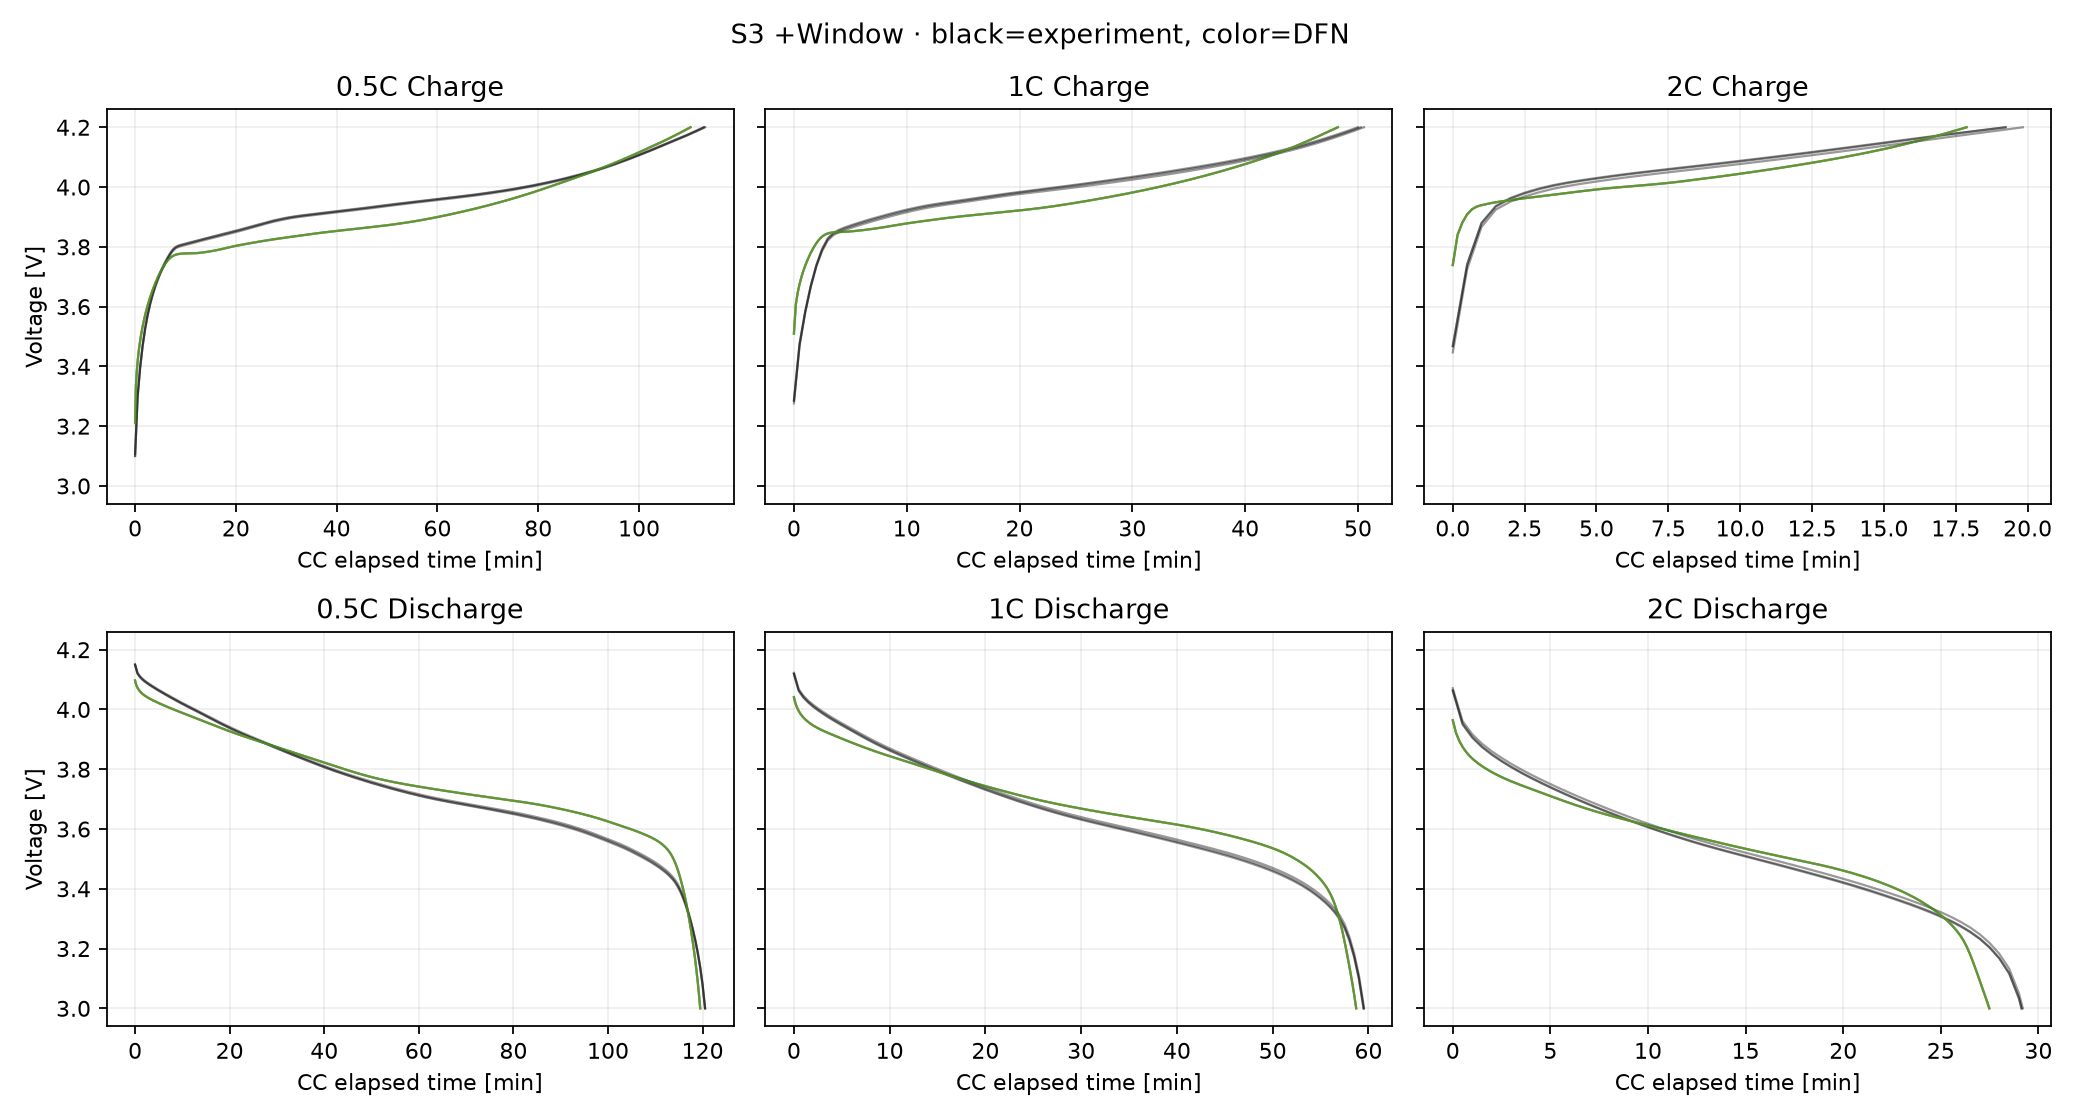

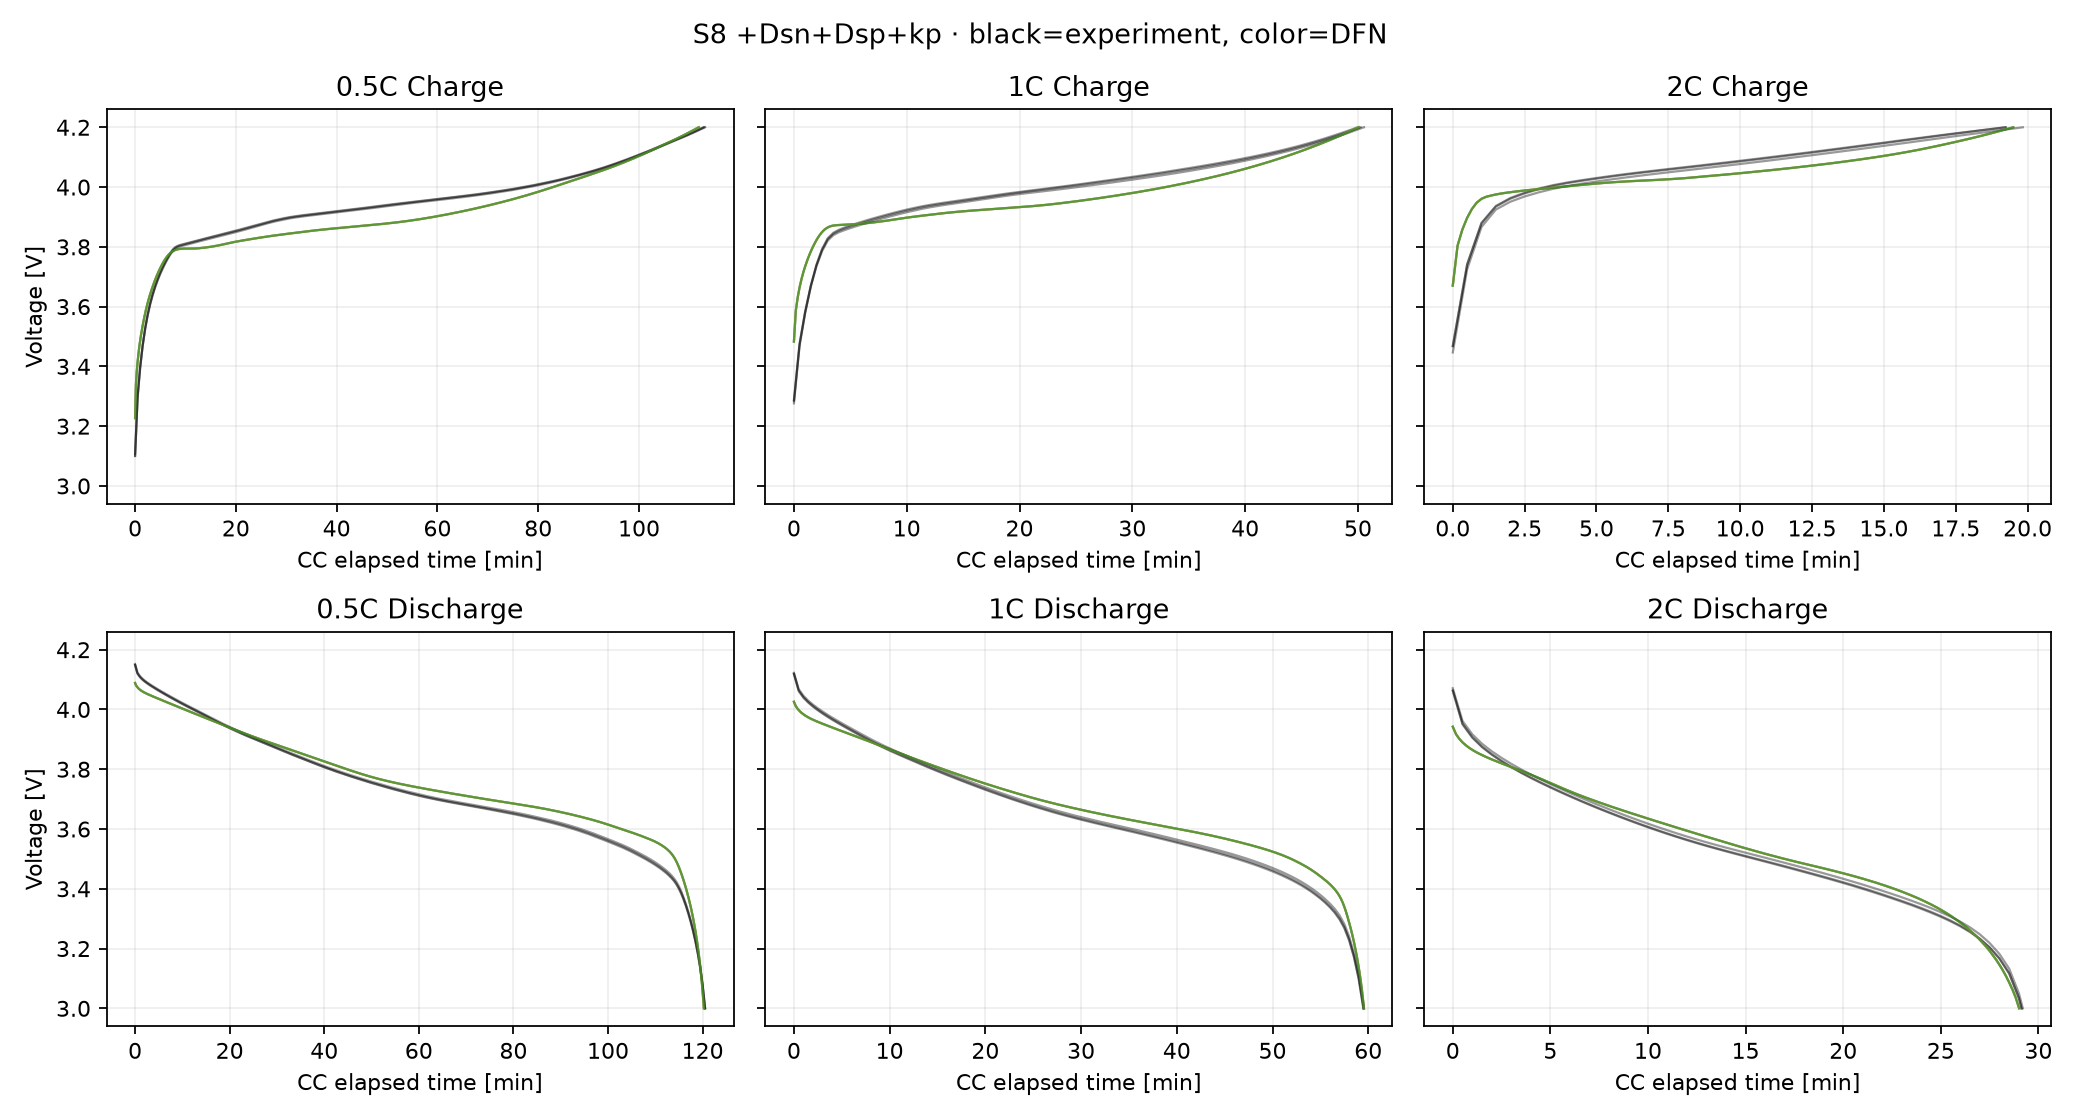

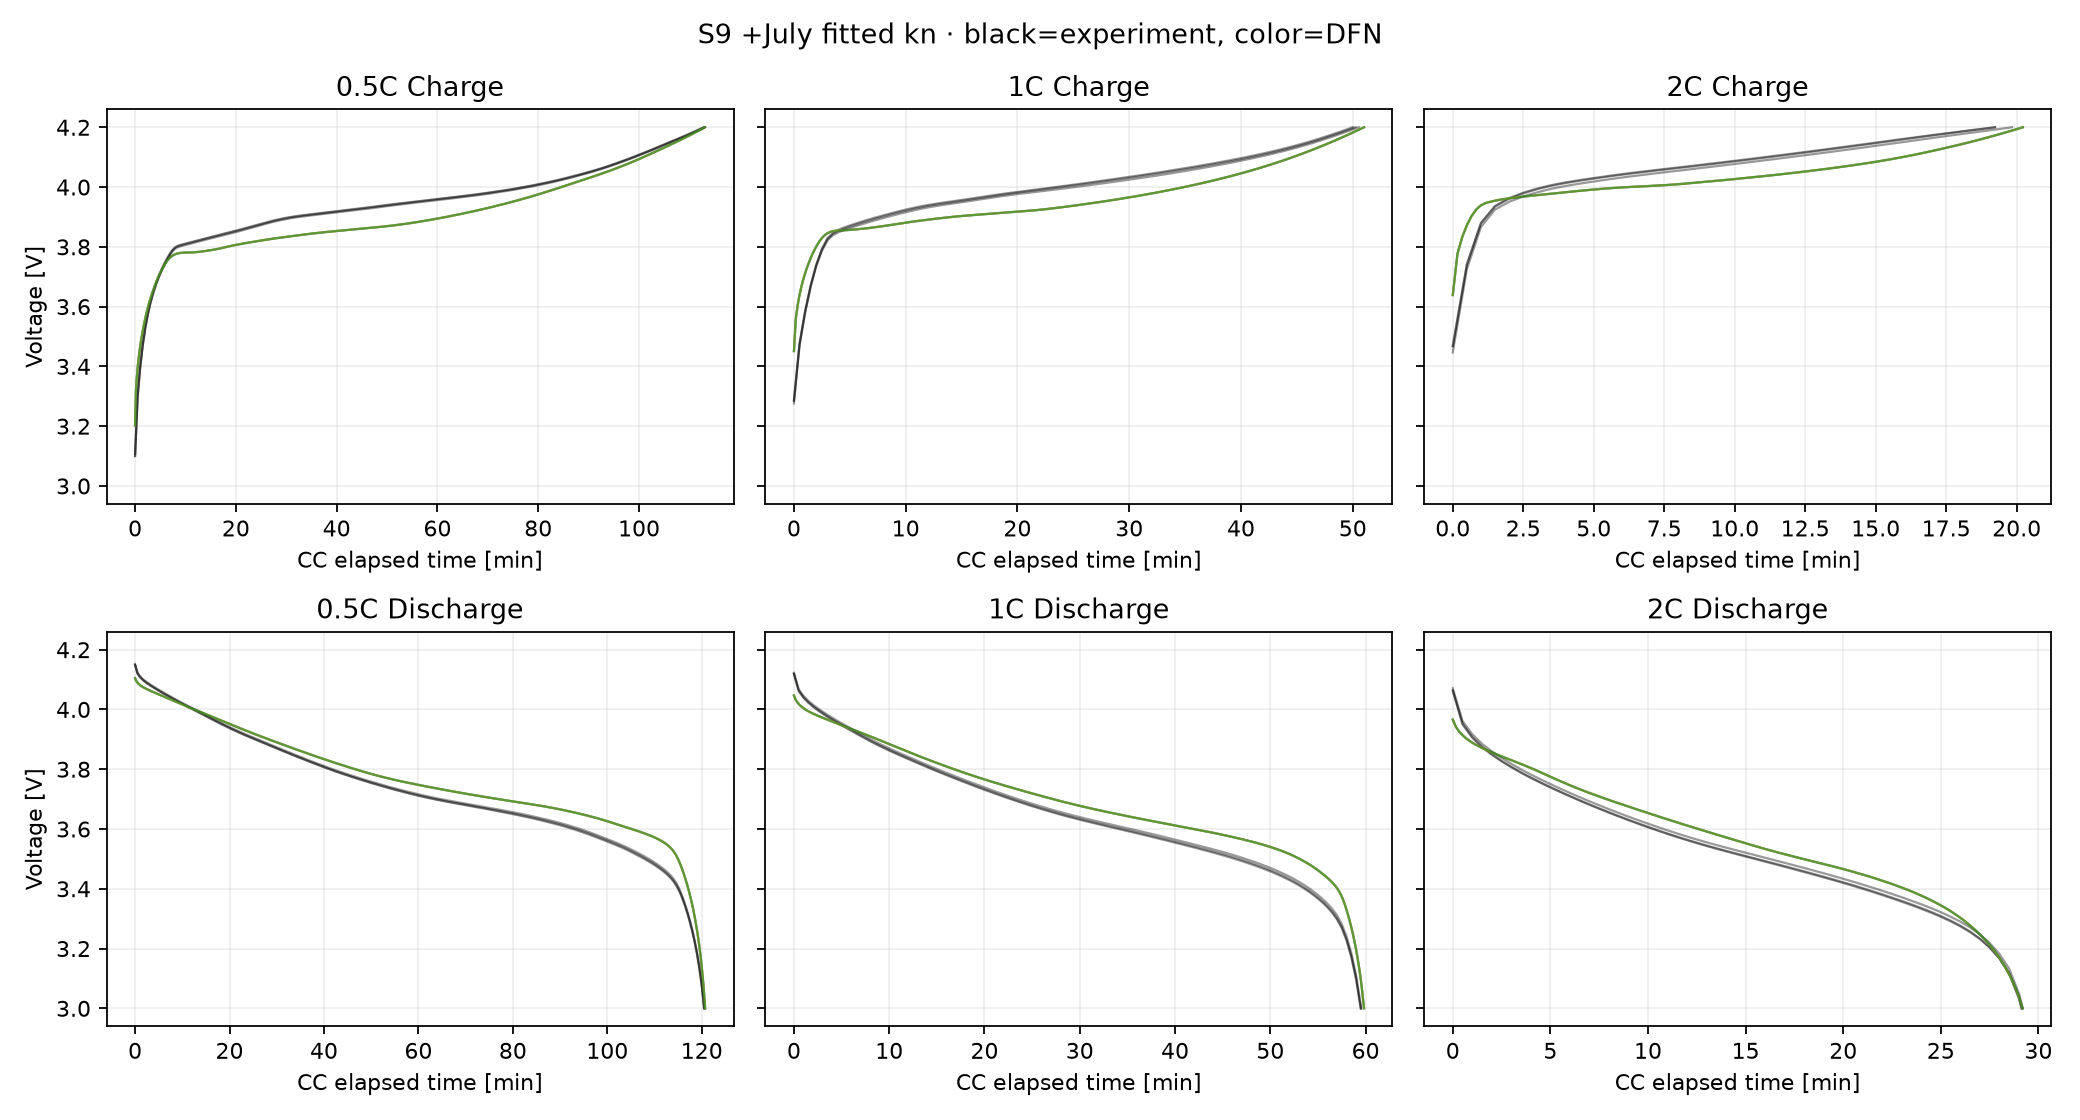

In [8]:
# 현대차 참고 노트북처럼 실험·모델 곡선을 겹쳐서 확인한다.
for name in ("S3 +Window","S8 +Dsn+Dsp+kp","S9 +July fitted kn"):
    if not any(k[0]==name for k in curves):
        continue
    fig,axes=plt.subplots(2,3,figsize=(13,7),sharey=True)
    for i,(rate,direction) in enumerate(((.5,"Charge"),(1.,"Charge"),(2.,"Charge"),
                                          (.5,"Discharge"),(1.,"Discharge"),(2.,"Discharge"))):
        ax=axes.ravel()[i]
        number=next(k for k,v in BRANCHES.items() if v==(rate,direction))
        for cell in JULY:
            if (name,cell,number) not in curves:
                continue
            te,ve,tm,vm=curves[(name,cell,number)]
            ax.plot(te,ve,color="black",alpha=.40,lw=1)
            ax.plot(tm,vm,alpha=.7,lw=1)
        ax.set_title(f"{rate:g}C {direction}"); ax.set_xlabel("CC elapsed time [min]")
        ax.grid(alpha=.2)
    axes[0,0].set_ylabel("Voltage [V]"); axes[1,0].set_ylabel("Voltage [V]")
    fig.suptitle(name+" · black=experiment, color=DFN")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/(name.replace(" ","_").replace("+","plus")+".png"),dpi=160)
    plt.show()


## 4. Hysteresis는 기본 모델에 바로 넣을까?

현재 음극 OCP는 Ai2020 **평형 곡선 하나**라 독립적인 graphite 방향별
절대 stoichiometry anchor가 없다. 양극은 기존 GITT의 lithiation/delithiation
두 branch가 있으므로 **양극 one-state hysteresis만 탐색적 진단**할 수 있다.
아래 셀은 `S8` 고정 파라미터와 같은 실제 7월 이력에서 양극 hysteresis를
켜고, 동일 시간 구간의 전압 RMSE와 cutoff를 비교한다. decay rate 3.2와
초기 hysteresis state 0은 측정·fitting된 값이 아니므로, RMSE가 줄더라도
곧바로 최종 물성으로 채택하지 않는다. 음극 전위의 실측 기준도 없다.

PyBaMM [one-state hysteresis 문서](https://docs.pybamm.org/en/latest/source/examples/notebooks/models/hysteresis-state-models.html)는
두 방향 OCP, 초기 상태, decay rate를 요구한다. OCP 측정에서는 휴지시간도
영향을 주므로 같은 휴지 조건의 branch 검증이 필요하다.


In [9]:
reference="S8 +Dsn+Dsp+kp"
hys_name="S8 +cathode hysteresis"
hys_spec=next(s for s in SCENARIOS if s[0]==reference)
hys_rows=[]
for cell in JULY:
    print("Hysteresis 진단:",cell,flush=True)
    try:
        step,record,by_num,_=simulate_history(cell,hys_spec,hys=True)
        for number in BRANCHES:
            metric,curve=compare_branch(cell,hys_name,number,step,record,by_num)
            hys_rows.append(metric)
            curves[(hys_name,cell,number)]=curve
    except Exception as exc:
        print("Hysteresis 실패:",repr(exc))
        failures_df=pd.concat([failures_df,pd.DataFrame([{"scenario":hys_name,"cell":cell,"error":repr(exc)}])],ignore_index=True)
if hys_rows:
    hys_metrics=pd.DataFrame(hys_rows)
    hys_metrics.to_csv(OUTPUT_DIR/"hysteresis_by_cell.csv",index=False)
    # 기준 S8과 hysteresis 계산이 모두 존재하는 동일 시간창에서 직접 비교
    pair=[]
    for cell in JULY:
        for number,(rate,direction) in BRANCHES.items():
            if (reference,cell,number) not in curves or (hys_name,cell,number) not in curves:
                continue
            te,ve,t0,v0=curves[(reference,cell,number)]
            _,_,t1,v1=curves[(hys_name,cell,number)]
            end=min(te[-1],t0[-1],t1[-1]); grid=np.linspace(0,end,100)
            measured=np.interp(grid,te,ve)
            for case,t,v in ((reference,t0,v0),(hys_name,t1,v1)):
                error=1000*(np.interp(grid,t,v)-measured)
                pair.append({"cell":cell,"rate_C":rate,"direction":direction,"scenario":case,
                             "RMSE_mV":float(np.sqrt(np.mean(error**2))),
                             "coverage_pct":100*end/te[-1]})
    hysteresis_compare=pd.DataFrame(pair)
    hysteresis_compare.to_csv(OUTPUT_DIR/"hysteresis_common_window.csv",index=False)
    display(hysteresis_compare.groupby(["rate_C","direction","scenario"]).agg(
        mean_RMSE_mV=("RMSE_mV","mean"),minimum_coverage_pct=("coverage_pct","min")).round(2))
failures_df.to_csv(OUTPUT_DIR/"failures.csv",index=False)


양극 one-state hysteresis γ=3.2, 초기 state=0 진단. 동일 시간창 RMSE (mV):


mean_RMSE_mV  minimum_coverage_pct
rate_C direction scenario                                                  
0.5    Charge    S8 +Dsn+Dsp+kp                 41.49                 98.61
                 S8 +cathode hysteresis         40.81                 98.61
       Discharge S8 +Dsn+Dsp+kp                 35.83                 99.54
                 S8 +cathode hysteresis         34.13                 99.54
1.0    Charge    S8 +Dsn+Dsp+kp                 49.98                 98.75
                 S8 +cathode hysteresis         49.13                 98.75
       Discharge S8 +Dsn+Dsp+kp                 40.90                 99.80
                 S8 +cathode hysteresis         38.38                 99.80
2.0    Charge    S8 +Dsn+Dsp+kp                 53.62                 97.88
                 S8 +cathode hysteresis         52.99                 97.88
       Discharge S8 +Dsn+Dsp+kp                 28.50                 99.11
                 S8 +cathode hysteresis         28.25                 99.11

## 해석 기준

전압 RMSE는 **모델·실험이 모두 계산된 CC 겹침 시간**에서만 유효하다.
`min_coverage_pct < 100`이면 조기 cutoff 뒤는 평가하지 않았으므로
전구간 RMSE나 SoC 10–80% 전체 성능으로 표현하지 않는다. CV 구간은
4.2 V로 제어되므로 전압 RMSE 대신 종료 시각과 전류를 별도로 확인해야 한다.
Hysteresis를 채택하려면 반복 양극 GITT branch와 decay rate, 초기 state를
독립적으로 확인하고, charge와 held-out discharge가 함께 개선돼야 한다.
2C 전압만 맞춰 음극 전위 정확성을 주장하지 않는다.
